<a href="https://colab.research.google.com/github/TarodinoAugusto/ZINC-Paraziquantel-similarity-search/blob/main/tcc_pipeline_v2_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TCC — Pipeline QSAR v2 (TGR e smHDAC8 · *Schistosoma mansoni*)

Versão corrigida do pipeline. O que muda em relação à v1:

1. **Valores censurados** (`IC50 > 30 µM`) deixam de ser tratados como medidas exatas: a regressão usa só `=`; a classificação usa censurados apenas quando o rótulo é inequívoco.
2. **Duplicatas após a padronização** são fundidas (mediana) e réplicas discordantes (> 1 unidade log) são descartadas.
3. **Seleção de variáveis e ajuste do PLS dentro da validação cruzada** (sem vazamento de informação).
4. **Validação por cluster (Butina)** além do 10-fold aleatório: mede o desempenho em química nova, que é o que a triagem exige.
5. **Descritores 3D** (PMI, NPR, raio de giro…) comparados por ablação com fingerprints 2D e descritores RDKit (cumpre o "QSAR 3D" da proposta).
6. **Classificação ativo/inativo (pIC50 ≥ 6)**: testa diretamente as hipóteses H1 e H2.
7. **Y-scrambling** e **domínio de aplicabilidade** (Tanimoto ao conjunto de treino).
8. **Triagem ZINC** com domínio de aplicabilidade, PAINS/Brenk e filtro de grupo de ligação ao zinco (HDAC8).

Execute de cima para baixo (*Ambiente de execução → Executar tudo*). Tempo típico no Colab gratuito: 30–45 min (use `FAST_MODE = True` na célula de parâmetros para um teste rápido).

In [1]:
%pip install -q rdkit chembl_webresource_client scikit-learn pandas numpy matplotlib scipy joblib tqdm

In [2]:
import os, glob, json, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy.stats import spearmanr
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **k): return x

from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Lipinski, rdMolDescriptors, MACCSkeys, AllChem, Descriptors3D
from rdkit.Chem import rdFingerprintGenerator
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit.Chem.FilterCatalog import FilterCatalog, FilterCatalogParams
from rdkit.ML.Cluster import Butina

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import (RandomForestRegressor, HistGradientBoostingRegressor,
                              RandomForestClassifier, HistGradientBoostingClassifier)
from sklearn.model_selection import (KFold, StratifiedKFold, GroupKFold, StratifiedGroupKFold,
                                     GridSearchCV, cross_val_predict)
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error, roc_auc_score,
                             average_precision_score, matthews_corrcoef, balanced_accuracy_score,
                             roc_curve, precision_recall_curve)

RDLogger.DisableLog('rdApp.*')
warnings.filterwarnings('ignore')

# ---------------- parâmetros do estudo ----------------
SEED = 42
TARGETS = {'TGR': 'CHEMBL6110', 'smHDAC8': 'CHEMBL3797017'}
THR_NM = 1000.0            # ativo = IC50 <= 1 µM (pIC50 >= 6), como na hipótese H1
PIC50_THR = 6.0
MAX_REPLICATE_RANGE = 1.0  # descarta estruturas com réplicas discordantes (> 1 log)
AD_THR = 0.40              # domínio de aplicabilidade: Tanimoto máx. (ECFP4) ao treino
AD_FLOOR = 0.30            # abaixo disto a previsão não é nem calculada na triagem
MIN_R2_VIABLE = 0.30       # modelo viável se R² por cluster >= 0,30 ...
MIN_RHO_VIABLE = 0.50      # ... OU Spearman por cluster >= 0,50 (poder de ranqueamento, o que a triagem usa)
MIN_AUC_VIABLE = 0.65      # AUC por cluster mínima para usar o classificador na triagem
N_PERM = 20                # permutações do Y-scrambling
FAST_MODE = False          # True = 2-3x mais rápido (menos árvores/iterações); use só para testar
N_TREES = 100 if FAST_MODE else 300
N_ITER = 80 if FAST_MODE else 200

for d in ['data', 'figuras', 'tabelas', 'models', 'zinc_libs']:
    os.makedirs(d, exist_ok=True)
print('Ambiente pronto.')

Ambiente pronto.


## 1. Coleta no ChEMBL e auditoria de censura

Se o arquivo `data/<alvo>/<alvo>_raw_activities.csv` já existir (runtime antigo), ele é reutilizado; caso contrário, baixa do ChEMBL.
A auditoria mostra quantos registros são censurados (`>`/`<`) e quais valores se repetem (patamares de ensaio).

In [3]:
from chembl_webresource_client.new_client import new_client

def load_raw(nome, chembl_id):
    os.makedirs(f'data/{nome}', exist_ok=True)
    path = f'data/{nome}/{nome}_raw_activities.csv'
    if os.path.exists(path):
        df = pd.read_csv(path)
        if 'standard_relation' in df.columns:
            return df
    res = new_client.activity.filter(target_chembl_id=chembl_id).filter(standard_type='IC50')
    df = pd.DataFrame.from_dict(res)
    df.to_csv(path, index=False)
    return df

RAW = {n: load_raw(n, t) for n, t in TARGETS.items()}
for n, df in RAW.items():
    print(f'== {n}: {len(df)} registros IC50')
    print('   relação (standard_relation):', df['standard_relation'].value_counts(dropna=False).to_dict())
    print('   unidades:', df['standard_units'].value_counts(dropna=False).to_dict())
    rep = pd.to_numeric(df['standard_value'], errors='coerce').value_counts().head(3)
    print('   valores mais repetidos (nM):', {float(k): int(v) for k, v in rep.items()})

== TGR: 59 registros IC50
   relação (standard_relation): {'=': 52, '>': 6, None: 1}
   unidades: {'nM': 58, None: 1}
   valores mais repetidos (nM): {50000.0: 7, 3500.0: 4, 2800.0: 3}
== smHDAC8: 260 registros IC50
   relação (standard_relation): {'=': 152, '>': 106, None: 2}
   unidades: {'nM': 258, None: 2}
   valores mais repetidos (nM): {30000.0: 106, 330.0: 4, 450.0: 3}


### 1b. (Opcional) Inventário de alvos de *Schistosoma* no ChEMBL

Responde duas perguntas: existe alvo de *S. haematobium* com dados de IC50 (lacuna da proposta)? Há ortólogos de TGR/HDAC8 em outras espécies para ampliar o conjunto?

In [4]:
def inventario(organismos=('Schistosoma mansoni', 'Schistosoma haematobium', 'Schistosoma japonicum')):
    rows = []
    for org in organismos:
        for t in new_client.target.search(org):
            if t.get('target_type') != 'SINGLE PROTEIN' or t.get('organism') != org:
                continue
            tid = t['target_chembl_id']
            try:
                n_ic50 = len(new_client.activity.filter(target_chembl_id=tid).filter(standard_type='IC50'))
            except Exception:
                n_ic50 = np.nan
            rows.append({'organismo': org, 'target_chembl_id': tid, 'alvo': t.get('pref_name'), 'n_IC50': n_ic50})
    return pd.DataFrame(rows).sort_values(['organismo', 'n_IC50'], ascending=[True, False])

INV = inventario()
print(INV.to_string(index=False))
INV.to_csv('tabelas/inventario_alvos_schistosoma.csv', index=False)

            organismo target_chembl_id                                                  alvo  n_IC50
Schistosoma japonicum    CHEMBL4105850                             Glutathione-S-transferase     111
  Schistosoma mansoni    CHEMBL3797017                                 Histone deacetylase 8     260
  Schistosoma mansoni       CHEMBL6110                     Thioredoxin glutathione reductase      59
  Schistosoma mansoni    CHEMBL4523950 Dihydroorotate dehydrogenase (quinone), mitochondrial      32
  Schistosoma mansoni    CHEMBL4523517                     NAD-dependent protein deacetylase      19
  Schistosoma mansoni    CHEMBL5169215                               Venus kinase receptor 2       3
  Schistosoma mansoni    CHEMBL4879549                              ATP-diphosphohydrolase 1       2
  Schistosoma mansoni    CHEMBL1293279                                Thioredoxin peroxidase       0
  Schistosoma mansoni    CHEMBL2363079      Voltage-activated calcium channel beta 1 subuni

## 2. Curadoria dos dados

- Padronização estrutural (maior fragmento, tautômero canônico, neutralização).
- **Regressão:** apenas valores exatos (`=`); medianas por estrutura padronizada; réplicas discordantes removidas.
- **Classificação (ativo = IC50 ≤ 1 µM):** inclui censurados quando o rótulo é inequívoco (`> X` com X ≥ 1 µM → inativo; `< X` com X ≤ 1 µM → ativo).
- O **funil** gerado é a tabela de curadoria para o capítulo de Métodos/Resultados.

In [5]:
_FRAG = rdMolStandardize.LargestFragmentChooser()
_UNCH = rdMolStandardize.Uncharger()
_TAUT = rdMolStandardize.TautomerEnumerator()

def standardize(smi):
    try:
        m = Chem.MolFromSmiles(smi)
        if m is None:
            return None
        m = _FRAG.choose(m)
        m = _TAUT.Canonicalize(m)
        m = _UNCH.uncharge(m)
        return Chem.MolToSmiles(m)
    except Exception:
        return None

def label_active(rel, v, thr=THR_NM):
    if rel == '=':
        return float(v <= thr)
    if rel in ('<', '<='):
        return 1.0 if v <= thr else np.nan
    if rel in ('>', '>='):
        return 0.0 if v >= thr else np.nan
    return np.nan

def curate(df):
    f = {}
    d = df.copy()
    f['1. registros IC50 brutos (ChEMBL)'] = len(d)
    d['standard_value'] = pd.to_numeric(d['standard_value'], errors='coerce')
    d['standard_relation'] = d['standard_relation'].fillna('=').astype(str).str.strip().str.strip('\'"')
    d = d[(d['standard_units'] == 'nM') & (d['standard_value'] > 0) & d['canonical_smiles'].notna()].copy()
    f['2. com valor > 0, unidade nM e SMILES'] = len(d)
    d['smiles_std'] = d['canonical_smiles'].map(standardize)
    d = d[d['smiles_std'].notna()].copy()
    f['3. SMILES padronizado com sucesso'] = len(d)
    f["    dos quais censurados (relação ≠ '=')"] = int((d['standard_relation'] != '=').sum())

    # ---- regressão: só valores exatos
    ex = d[d['standard_relation'] == '='].copy()
    f["4. valores exatos ('=') — base da regressão"] = len(ex)
    ex['pIC50'] = -np.log10(ex['standard_value'] * 1e-9)
    g = ex.groupby('smiles_std').agg(pIC50=('pIC50', 'median'), pmin=('pIC50', 'min'), pmax=('pIC50', 'max'),
                                     n_rep=('pIC50', 'count'),
                                     molecule_chembl_id=('molecule_chembl_id', 'first')).reset_index()
    f['5. estruturas únicas (após padronização)'] = len(g)
    g = g[(g['pmax'] - g['pmin']) <= MAX_REPLICATE_RANGE]
    f[f'6. sem réplicas discordantes (> {MAX_REPLICATE_RANGE:g} log)'] = len(g)
    reg = g[['molecule_chembl_id', 'smiles_std', 'pIC50', 'n_rep']].reset_index(drop=True)

    # ---- classificação: exatos + censurados inequívocos
    d['label'] = [label_active(r, v) for r, v in zip(d['standard_relation'], d['standard_value'])]
    c = d[d['label'].notna()]
    cg = c.groupby('smiles_std').agg(y=('label', 'mean'), molecule_chembl_id=('molecule_chembl_id', 'first')).reset_index()
    cg = cg[cg['y'].isin([0.0, 1.0])].copy()
    cg['y'] = cg['y'].astype(int)
    f['7. classificação: estruturas com rótulo inequívoco'] = len(cg)
    f['    ativos / inativos (IC50 ≤ 1 µM)'] = f"{int(cg['y'].sum())} / {int((1 - cg['y']).sum())}"
    return {'reg': reg, 'cls': cg.reset_index(drop=True), 'funil': pd.Series(f)}

CUR = {n: curate(df) for n, df in RAW.items()}
FUNIL = pd.DataFrame({n: c['funil'] for n, c in CUR.items()})
print(FUNIL.to_string())
FUNIL.to_csv('tabelas/funil_curadoria.csv')
for n in TARGETS:
    r = CUR[n]['reg']
    print(f"\n{n} (regressão): N={len(r)} | pIC50 média={r['pIC50'].mean():.2f} dp={r['pIC50'].std():.2f} "
          f"min={r['pIC50'].min():.2f} máx={r['pIC50'].max():.2f} | ≥6: {(r['pIC50'] >= 6).sum()}")

                                                        TGR   smHDAC8
1. registros IC50 brutos (ChEMBL)                        59       260
2. com valor > 0, unidade nM e SMILES                    58       258
3. SMILES padronizado com sucesso                        58       258
    dos quais censurados (relação ≠ '=')                  6       106
4. valores exatos ('=') — base da regressão              52       152
5. estruturas únicas (após padronização)                 51       107
6. sem réplicas discordantes (> 1 log)                   51       106
7. classificação: estruturas com rótulo inequívoco       57       203
    ativos / inativos (IC50 ≤ 1 µM)                 19 / 38  74 / 129

TGR (regressão): N=51 | pIC50 média=5.78 dp=0.88 min=4.24 máx=8.00 | ≥6: 19

smHDAC8 (regressão): N=106 | pIC50 média=6.22 dp=0.68 min=4.30 máx=7.17 | ≥6: 74


## 3. Descritores moleculares

Blocos: **ECFP4** (2048 bits), **MACCS** (167), **RDKit 2D** (~200 descritores físico-químicos/topológicos), **3D** (PMI1–3, NPR1–2, raio de giro, fator de forma inercial, excentricidade, assimetria, esfericidade — calculados na conformação de menor energia MMFF entre 5 conformeros ETKDGv3) e **Lipinski** (para drug-likeness).

In [6]:
_ECFP = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
_DESC = Descriptors._descList
D3_NAMES = ['PMI1', 'PMI2', 'PMI3', 'NPR1', 'NPR2', 'RadiusOfGyration', 'InertialShapeFactor',
            'Eccentricity', 'Asphericity', 'SpherocityIndex']
_D3_FN = [Descriptors3D.PMI1, Descriptors3D.PMI2, Descriptors3D.PMI3, Descriptors3D.NPR1, Descriptors3D.NPR2,
          Descriptors3D.RadiusOfGyration, Descriptors3D.InertialShapeFactor, Descriptors3D.Eccentricity,
          Descriptors3D.Asphericity, Descriptors3D.SpherocityIndex]

def block_ecfp(mols):
    if len(mols) == 0:
        return np.zeros((0, 2048), dtype=np.uint8)
    return np.vstack([_ECFP.GetFingerprintAsNumPy(m) for m in mols]).astype(np.uint8)

def block_maccs(mols):
    return np.array([list(MACCSkeys.GenMACCSKeys(m)) for m in mols], dtype=np.uint8).reshape(len(mols), 167)

def block_rdkit2d(mols):
    names = [n for n, _ in _DESC]
    out = np.full((len(mols), len(names)), np.nan, dtype=np.float64)
    for i, m in enumerate(tqdm(mols, desc='RDKit2D', leave=False)):
        for j, (_, fn) in enumerate(_DESC):
            try:
                out[i, j] = fn(m)
            except Exception:
                pass
    out[~np.isfinite(out)] = np.nan
    return np.clip(out, -1e6, 1e6), names

def block_3d(mols, n_conf=5):
    out = np.full((len(mols), len(D3_NAMES)), np.nan, dtype=np.float64)
    for i, m in enumerate(tqdm(mols, desc='3D', leave=False)):
        try:
            mh = Chem.AddHs(m)
            p = AllChem.ETKDGv3()
            p.randomSeed = SEED
            cids = list(AllChem.EmbedMultipleConfs(mh, n_conf, p))
            if not cids:
                continue
            res = AllChem.MMFFOptimizeMoleculeConfs(mh, maxIters=500)
            en = np.array([e for _, e in res], dtype=float)
            best = int(np.argmin(en)) if len(en) == len(cids) else 0
            out[i] = [fn(mh, confId=int(cids[best])) for fn in _D3_FN]
        except Exception:
            pass
    return out, list(D3_NAMES)

PHYS_NAMES = ['MW', 'LogP', 'HBD', 'HBA', 'TPSA', 'RotB', 'AromRings', 'FracCSP3', 'HeavyAtoms']
def block_phys(mols):
    rows = [[Descriptors.MolWt(m), Descriptors.MolLogP(m), Lipinski.NumHDonors(m), Lipinski.NumHAcceptors(m),
             Descriptors.TPSA(m), Lipinski.NumRotatableBonds(m), rdMolDescriptors.CalcNumAromaticRings(m),
             rdMolDescriptors.CalcFractionCSP3(m), m.GetNumHeavyAtoms()] for m in mols]
    return np.array(rows, dtype=float).reshape(len(mols), len(PHYS_NAMES)), list(PHYS_NAMES)

def lipinski_violations(phys):
    mw, logp, hbd, hba = phys[:, 0], phys[:, 1], phys[:, 2], phys[:, 3]
    return (mw > 500).astype(int) + (logp > 5).astype(int) + (hbd > 5).astype(int) + (hba > 10).astype(int)

FEATURE_SETS = {
    'FP2D':             ['ecfp4', 'maccs'],
    'RDKIT2D':          ['rdkit2d'],
    'RDKIT2D+3D':       ['rdkit2d', 'd3'],
    'FP2D+RDKIT2D':     ['ecfp4', 'maccs', 'rdkit2d'],
    'FP2D+RDKIT2D+3D':  ['ecfp4', 'maccs', 'rdkit2d', 'd3'],
}

def featurize(mols, blocks):
    out = {}
    for b in blocks:
        if b == 'ecfp4':
            out[b] = (block_ecfp(mols), [f'ECFP4_{i}' for i in range(2048)])
        elif b == 'maccs':
            out[b] = (block_maccs(mols), [f'MACCS_{i}' for i in range(167)])
        elif b == 'rdkit2d':
            out[b] = block_rdkit2d(mols)
        elif b == 'd3':
            out[b] = block_3d(mols)
        elif b == 'phys':
            out[b] = block_phys(mols)
    return out

def assemble(blocks, setname, idx=None):
    mats, names = [], []
    for b in FEATURE_SETS[setname]:
        M, N = blocks[b]
        mats.append(np.asarray(M if idx is None else M[idx], dtype=np.float64))
        names += list(N)
    return np.hstack(mats), names

def build_features(nome):
    smi = sorted(set(CUR[nome]['reg']['smiles_std']) | set(CUR[nome]['cls']['smiles_std']))
    mols = [Chem.MolFromSmiles(s) for s in smi]
    print(f'{nome}: {len(smi)} estruturas — calculando descritores...')
    blocks = featurize(mols, ['ecfp4', 'maccs', 'rdkit2d', 'd3', 'phys'])
    falha3d = float(np.isnan(blocks['d3'][0]).all(axis=1).mean() * 100)
    print(f'   falha na geração 3D: {falha3d:.1f}% das estruturas')
    return {'smiles': smi, 'index': {s: i for i, s in enumerate(smi)}, 'blocks': blocks}

FEATS = {n: build_features(n) for n in TARGETS}

def X_for(nome, smiles, setname):
    f = FEATS[nome]
    idx = [f['index'][s] for s in smiles]
    return assemble(f['blocks'], setname, idx)

def ecfp_of(nome, smiles):
    f = FEATS[nome]
    return f['blocks']['ecfp4'][0][[f['index'][s] for s in smiles]]

# ---- Lipinski nos conjuntos de regressão (tabela para o TCC)
LIP = []
for n in TARGETS:
    reg = CUR[n]['reg']
    ph = FEATS[n]['blocks']['phys'][0][[FEATS[n]['index'][s] for s in reg['smiles_std']]]
    v = lipinski_violations(ph)
    LIP.append({'alvo': n, 'N': len(reg), '0 violações': int((v == 0).sum()), '1 violação': int((v == 1).sum()),
                '≥2 violações': int((v >= 2).sum()), 'drug-like (≤1)': f'{(v <= 1).mean() * 100:.1f}%'})
LIP = pd.DataFrame(LIP)
print(LIP.to_string(index=False))
LIP.to_csv('tabelas/lipinski_conjuntos.csv', index=False)

TGR: 57 estruturas — calculando descritores...


RDKit2D:   0%|          | 0/57 [00:00<?, ?it/s]

3D:   0%|          | 0/57 [00:00<?, ?it/s]

   falha na geração 3D: 0.0% das estruturas
smHDAC8: 204 estruturas — calculando descritores...


RDKit2D:   0%|          | 0/204 [00:00<?, ?it/s]

3D:   0%|          | 0/204 [00:00<?, ?it/s]

   falha na geração 3D: 0.0% das estruturas
   alvo   N  0 violações  1 violação  ≥2 violações drug-like (≤1)
    TGR  51           48           3             0         100.0%
smHDAC8 106           95           9             2          98.1%


## 4. Divisão treino/teste (Kennard-Stone) e grupos por cluster

- Kennard-Stone (80/20) sobre ECFP4+MACCS, como no artigo de referência (implementação própria, sem dependências extras).
- **Atenção:** o Kennard-Stone coloca os compostos mais "centrais" no teste → teste *fácil* (interpolação). Por isso o desempenho é reportado também por **validação cruzada por cluster (Butina sobre ECFP4; o corte de distância é reduzido automaticamente se a série for muito homogênea)**, que simula química nova.

In [7]:
def tanimoto_matrix(A, B=None):
    A = A.astype(np.float32)
    B = A if B is None else B.astype(np.float32)
    inter = A @ B.T
    union = A.sum(1)[:, None] + B.sum(1)[None, :] - inter
    return inter / np.maximum(union, 1)

def max_tanimoto(A, B, chunk=4000):
    return np.concatenate([tanimoto_matrix(A[i:i + chunk], B).max(axis=1) for i in range(0, len(A), chunk)])

def ks_split(X, test_frac=0.2):
    X = np.asarray(X, dtype=np.float32)
    n = len(X)
    n_train = n - int(np.ceil(test_frac * n))
    from sklearn.metrics import pairwise_distances
    D = pairwise_distances(X)
    i, j = np.unravel_index(np.argmax(D), D.shape)
    sel = [int(i), int(j)]
    mind = np.minimum(D[i], D[j])
    while len(sel) < n_train:
        mind[sel] = -1
        k = int(np.argmax(mind))
        sel.append(k)
        mind = np.minimum(mind, D[k])
    tr = np.array(sorted(sel))
    te = np.setdiff1d(np.arange(n), tr)
    return tr, te

def cluster_groups(E, cutoff=0.6, min_groups=5):
    """Butina sobre 1-Tanimoto(ECFP4). Se houver menos de `min_groups` clusters (série muito homogênea),
    reduz o corte de distância até obtê-los; em último caso usa blocos sequenciais (cutoff=None)."""
    n = len(E)
    dist = 1 - tanimoto_matrix(E)
    dl = [dist[i, j] for i in range(1, n) for j in range(i)]
    used, clusters = None, []
    for c in [cutoff, 0.5, 0.4, 0.3, 0.2, 0.1]:
        clusters = Butina.ClusterData(dl, n, c, isDistData=True)
        if len(clusters) >= min_groups:
            used = c
            break
    if used is None:
        return np.arange(n) % min_groups, None
    g = np.zeros(n, dtype=int)
    for ci, cl in enumerate(clusters):
        g[list(cl)] = ci
    return g, used

SPLIT, SPLIT_C, GROUPS, GROUPS_C, GROUP_CUT = {}, {}, {}, {}, {}
for n in TARGETS:
    for key, df, S, G in [('reg', CUR[n]['reg'], SPLIT, GROUPS), ('cls', CUR[n]['cls'], SPLIT_C, GROUPS_C)]:
        E = X_for(n, df['smiles_std'], 'FP2D')[0]
        tr, te = ks_split(E)
        S[n] = {'train': df.iloc[tr].reset_index(drop=True), 'test': df.iloc[te].reset_index(drop=True)}
        G[n], GROUP_CUT[(n, key)] = cluster_groups(ecfp_of(n, S[n]['train']['smiles_std']))
    r = SPLIT[n]
    cut = GROUP_CUT[(n, 'reg')]
    print(f"{n}: regressão treino={len(r['train'])} teste={len(r['test'])} "
          f"(pIC50 teste: média={r['test']['pIC50'].mean():.2f}, dp={r['test']['pIC50'].std():.2f} | "
          f"treino: média={r['train']['pIC50'].mean():.2f}, dp={r['train']['pIC50'].std():.2f}) "
          f"| clusters no treino={len(np.unique(GROUPS[n]))} "
          + (f"(corte de distância {cut}; Tanimoto ≥ {1 - cut:.1f} no mesmo cluster)" if cut is not None
             else "(série homogênea demais: blocos sequenciais — validação por cluster pouco informativa)"))
    c = SPLIT_C[n]
    print(f"      classificação treino={len(c['train'])} (ativos={int(c['train']['y'].sum())}) "
          f"teste={len(c['test'])} (ativos={int(c['test']['y'].sum())})")

TGR: regressão treino=40 teste=11 (pIC50 teste: média=5.35, dp=0.50 | treino: média=5.90, dp=0.93) | clusters no treino=16 (corte de distância 0.6; Tanimoto ≥ 0.4 no mesmo cluster)
      classificação treino=45 (ativos=17) teste=12 (ativos=2)
smHDAC8: regressão treino=84 teste=22 (pIC50 teste: média=6.58, dp=0.50 | treino: média=6.12, dp=0.69) | clusters no treino=25 (corte de distância 0.6; Tanimoto ≥ 0.4 no mesmo cluster)
      classificação treino=162 (ativos=55) teste=41 (ativos=19)


## 5. Modelos de regressão — ablação de descritores com validação honesta

Para cada **conjunto de descritores × algoritmo (PLS, RF, HGB)**:
- 10-fold × 3 repetições (validação aleatória, como na proposta);
- 5-fold **por cluster** (química nova).

Remoção de variáveis constantes, imputação e o ajuste de `n_components` do PLS acontecem **dentro** de cada dobra. O conjunto de descritores de cada família é escolhido pelo **R² por cluster** (critério conservador). Um modelo é **viável** para a triagem se R² por cluster ≥ 0,30 **ou** Spearman por cluster ≥ 0,50 (a triagem depende de ranqueamento).

In [8]:
def make_reg(name):
    pre = [('imp', SimpleImputer(strategy='median')), ('var', VarianceThreshold(0.0))]
    if name == 'PLS':
        pipe = Pipeline(pre + [('sc', StandardScaler()), ('pls', PLSRegression(n_components=2, scale=False))])
        return GridSearchCV(pipe, {'pls__n_components': [1, 2, 3, 4, 5, 6]},
                            cv=KFold(5, shuffle=True, random_state=SEED), scoring='neg_root_mean_squared_error')
    if name == 'RF':
        return Pipeline(pre + [('m', RandomForestRegressor(n_estimators=N_TREES, max_features=0.3, min_samples_leaf=2,
                                                           n_jobs=-1, random_state=SEED))])
    if name == 'HGB':
        return Pipeline(pre + [('m', HistGradientBoostingRegressor(max_depth=4, min_samples_leaf=3, learning_rate=0.05,
                                                                   max_iter=N_ITER, l2_regularization=1.0,
                                                                   random_state=SEED))])
    raise ValueError(name)

def cv_random(est, X, y, n_rep=3, k=10):
    return np.array([np.ravel(cross_val_predict(clone(est), X, y, cv=KFold(k, shuffle=True, random_state=SEED + r)))
                     for r in range(n_rep)])

def cv_cluster(est, X, y, groups, k=5):
    k = int(max(2, min(k, len(np.unique(groups)))))
    return np.ravel(cross_val_predict(clone(est), X, y, cv=GroupKFold(n_splits=k), groups=groups))

def ablation(nome):
    tr = SPLIT[nome]['train']
    y = tr['pIC50'].values
    rows, store = [], {}
    for fs in FEATURE_SETS:
        X, _ = X_for(nome, tr['smiles_std'], fs)
        for mn in ['PLS', 'RF', 'HGB']:
            est = make_reg(mn)
            Pr = cv_random(est, X, y)
            Pc = cv_cluster(est, X, y, GROUPS[nome])
            r2s = [r2_score(y, p) for p in Pr]
            rows.append({'alvo': nome, 'conjunto': fs, 'modelo': mn, 'n_features': X.shape[1],
                         'R2_CV10x3': np.mean(r2s), 'dp_R2': np.std(r2s),
                         'RMSE_CV10x3': np.mean([np.sqrt(mean_squared_error(y, p)) for p in Pr]),
                         'R2_CV_cluster': r2_score(y, Pc), 'RMSE_CV_cluster': np.sqrt(mean_squared_error(y, Pc)),
                         'Spearman_cluster': spearmanr(y, Pc)[0] if np.std(Pc) > 0 else np.nan})
            store[(fs, mn)] = {'rand': Pr.mean(axis=0), 'clu': Pc}
        print(f'   {nome}: {fs} ✓')
    return pd.DataFrame(rows), store

ABL, ABL_P = {}, {}
for n in TARGETS:
    print(f'Ablação {n} (N treino = {len(SPLIT[n]["train"])})')
    ABL[n], ABL_P[n] = ablation(n)
ABL_ALL = pd.concat(ABL.values(), ignore_index=True)
ABL_ALL.round(3).to_csv('tabelas/ablacao_regressao.csv', index=False)
for n in TARGETS:
    print(f'\n=== {n} — ablação (ordenada por R² por cluster) ===')
    print(ABL[n].sort_values('R2_CV_cluster', ascending=False).round(3).to_string(index=False))

Ablação TGR (N treino = 40)
   TGR: FP2D ✓
   TGR: RDKIT2D ✓
   TGR: RDKIT2D+3D ✓
   TGR: FP2D+RDKIT2D ✓
   TGR: FP2D+RDKIT2D+3D ✓
Ablação smHDAC8 (N treino = 84)
   smHDAC8: FP2D ✓
   smHDAC8: RDKIT2D ✓
   smHDAC8: RDKIT2D+3D ✓
   smHDAC8: FP2D+RDKIT2D ✓
   smHDAC8: FP2D+RDKIT2D+3D ✓

=== TGR — ablação (ordenada por R² por cluster) ===
alvo        conjunto modelo  n_features  R2_CV10x3  dp_R2  RMSE_CV10x3  R2_CV_cluster  RMSE_CV_cluster  Spearman_cluster
 TGR            FP2D     RF        2215      0.217  0.054        0.812          0.201            0.820             0.421
 TGR    FP2D+RDKIT2D     RF        2432      0.164  0.052        0.839          0.194            0.824             0.410
 TGR      RDKIT2D+3D     RF         227      0.181  0.061        0.830          0.190            0.826             0.434
 TGR FP2D+RDKIT2D+3D     RF        2442      0.186  0.068        0.827          0.187            0.827             0.410
 TGR         RDKIT2D     RF         217      0.154  0.05

### 5b. Modelos finais, teste externo e consenso

In [9]:
def reg_metrics(y, p):
    return {'R2': r2_score(y, p), 'RMSE': float(np.sqrt(mean_squared_error(y, p))), 'MAE': mean_absolute_error(y, p),
            'Spearman': spearmanr(y, p)[0] if np.std(p) > 0 else np.nan}

FINAL = {}
for n in TARGETS:
    tr, te = SPLIT[n]['train'], SPLIT[n]['test']
    ytr = tr['pIC50'].values
    FINAL[n] = {}
    for mn in ['PLS', 'RF', 'HGB']:
        row = ABL[n][ABL[n].modelo == mn].sort_values('R2_CV_cluster', ascending=False).iloc[0]
        fs = row['conjunto']
        Xtr, _ = X_for(n, tr['smiles_std'], fs)
        Xte, _ = X_for(n, te['smiles_std'], fs)
        est = make_reg(mn).fit(Xtr, ytr)
        FINAL[n][mn] = {'est': est, 'set': fs, 'pred_test': np.ravel(est.predict(Xte)),
                        'R2_CV': float(row['R2_CV10x3']), 'R2_cluster': float(row['R2_CV_cluster']),
                        'rho_cluster': float(row['Spearman_cluster']),
                        'viavel': bool(row['R2_CV_cluster'] >= MIN_R2_VIABLE or row['Spearman_cluster'] >= MIN_RHO_VIABLE)}

rows, CONS = [], {}
for n in TARGETS:
    yte, ytr = SPLIT[n]['test']['pIC50'].values, SPLIT[n]['train']['pIC50'].values
    rows.append({'alvo': n, 'modelo': 'baseline (média do treino)', 'conjunto': '-', 'R2_CV10x3': np.nan,
                 'R2_cluster': np.nan, 'viavel': '-', **reg_metrics(yte, np.full_like(yte, ytr.mean(), dtype=float))})
    for mn, d in FINAL[n].items():
        rows.append({'alvo': n, 'modelo': mn, 'conjunto': d['set'], 'R2_CV10x3': d['R2_CV'],
                     'R2_cluster': d['R2_cluster'], 'rho_cluster': d['rho_cluster'], 'viavel': d['viavel'],
                     **reg_metrics(yte, d['pred_test'])})
    P = [d['pred_test'] for d in FINAL[n].values() if d['viavel']]
    if P:
        P = np.vstack(P)
        cons = P.mean(axis=0)
        sd = P.std(axis=0, ddof=1) if len(P) > 1 else np.zeros(P.shape[1])
        CONS[n] = pd.DataFrame({'obs': yte, 'pred_mean': cons, 'pred_sd': sd, 'CV%': sd / cons * 100})
        rows.append({'alvo': n, 'modelo': f'consenso ({len(P)} modelos viáveis)', 'conjunto': '-', 'R2_CV10x3': np.nan,
                     'R2_cluster': np.nan, 'viavel': True, **reg_metrics(yte, cons)})
    else:
        rows.append({'alvo': n, 'modelo': 'consenso', 'conjunto': '-', 'R2_CV10x3': np.nan, 'R2_cluster': np.nan,
                     'viavel': False, 'R2': np.nan, 'RMSE': np.nan, 'MAE': np.nan, 'Spearman': np.nan})
TESTE = pd.DataFrame(rows)
print(TESTE.round(3).to_string(index=False))
TESTE.round(3).to_csv('tabelas/desempenho_teste_regressao.csv', index=False)
for n in TARGETS:
    if n in CONS:
        print(f"\n{n}: CV% médio entre modelos (teste) = {CONS[n]['CV%'].mean():.2f}%")
    else:
        print(f'\n{n}: NENHUM modelo atingiu R² por cluster ≥ {MIN_R2_VIABLE} nem Spearman por cluster ≥ {MIN_RHO_VIABLE} — reportar como resultado exploratório/negativo.')

   alvo                     modelo        conjunto  R2_CV10x3  R2_cluster viavel     R2  RMSE   MAE  Spearman  rho_cluster
    TGR baseline (média do treino)               -        NaN         NaN      - -1.363 0.729 0.661       NaN          NaN
    TGR                        PLS FP2D+RDKIT2D+3D     -0.048      -0.092  False  0.186 0.428 0.356     0.400        0.292
    TGR                         RF            FP2D      0.217       0.201  False  0.305 0.395 0.335     0.782        0.421
    TGR                        HGB FP2D+RDKIT2D+3D      0.003       0.134  False  0.579 0.308 0.256     0.782        0.392
    TGR                   consenso               -        NaN         NaN  False    NaN   NaN   NaN       NaN          NaN
smHDAC8 baseline (média do treino)               -        NaN         NaN      - -0.858 0.667 0.603       NaN          NaN
smHDAC8                        PLS            FP2D      0.610       0.056  False  0.622 0.300 0.252     0.401        0.200
smHDAC8         

## 6. Classificação ativo/inativo (IC50 ≤ 1 µM) — hipóteses H1 e H2

Usa todos os rótulos inequívocos (inclusive censurados). Métricas: ROC-AUC, PR-AUC (comparar com a prevalência), MCC e acurácia balanceada; validação aleatória e **por cluster**.

In [10]:
def make_cls(name):
    pre = [('imp', SimpleImputer(strategy='median')), ('var', VarianceThreshold(0.0))]
    if name == 'RF':
        return Pipeline(pre + [('m', RandomForestClassifier(n_estimators=N_TREES, max_features=0.3, min_samples_leaf=2,
                                                            class_weight='balanced_subsample', n_jobs=-1,
                                                            random_state=SEED))])
    return Pipeline(pre + [('m', HistGradientBoostingClassifier(max_depth=4, min_samples_leaf=3, learning_rate=0.05,
                                                                max_iter=N_ITER, l2_regularization=1.0,
                                                                class_weight='balanced', random_state=SEED))])

def cv_cls(est, X, y, groups=None, k=10):
    if groups is None:
        kk = int(max(2, min(k, y.sum(), (1 - y).sum())))
        cv = StratifiedKFold(kk, shuffle=True, random_state=SEED)
        P = cross_val_predict(clone(est), X, y, cv=cv, method='predict_proba')
    else:
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
        P = cross_val_predict(clone(est), X, y, cv=cv, groups=groups, method='predict_proba')
    return P[:, 1]

CLS_ABL, CLS_SET, CLS_FINAL, CLS_ROWS = {}, {}, {}, []
for n in TARGETS:
    ctr, cte = SPLIT_C[n]['train'], SPLIT_C[n]['test']
    y, yt = ctr['y'].values, cte['y'].values
    rows = []
    for fs in FEATURE_SETS:
        X, _ = X_for(n, ctr['smiles_std'], fs)
        pr = cv_cls(make_cls('RF'), X, y)
        pc = cv_cls(make_cls('RF'), X, y, groups=GROUPS_C[n])
        rows.append({'alvo': n, 'conjunto': fs, 'AUC_CV': roc_auc_score(y, pr), 'PRAUC_CV': average_precision_score(y, pr),
                     'AUC_cluster': roc_auc_score(y, pc), 'PRAUC_cluster': average_precision_score(y, pc),
                     'prevalência_treino': y.mean()})
    CLS_ABL[n] = pd.DataFrame(rows)
    best = CLS_ABL[n].sort_values('AUC_cluster', ascending=False).iloc[0]
    fs = best['conjunto']
    CLS_SET[n] = fs
    Xtr, _ = X_for(n, ctr['smiles_std'], fs)
    Xte, _ = X_for(n, cte['smiles_std'], fs)
    CLS_FINAL[n] = {}
    for mn in ['RF', 'HGB']:
        est = make_cls(mn).fit(Xtr, y)
        CLS_FINAL[n][mn] = {'est': est, 'prob_test': est.predict_proba(Xte)[:, 1]}
    prob = np.mean([d['prob_test'] for d in CLS_FINAL[n].values()], axis=0)
    pred = (prob >= 0.5).astype(int)
    ok = len(np.unique(yt)) == 2
    CLS_ROWS.append({'alvo': n, 'conjunto': fs, 'AUC_cluster(CV)': best['AUC_cluster'],
                     'N_teste': len(yt), 'ativos_teste': int(yt.sum()), 'prevalência_teste': yt.mean(),
                     'AUC_teste': roc_auc_score(yt, prob) if ok else np.nan,
                     'PRAUC_teste': average_precision_score(yt, prob) if ok else np.nan,
                     'MCC_teste': matthews_corrcoef(yt, pred), 'BalAcc_teste': balanced_accuracy_score(yt, pred),
                     'viavel_para_triagem': bool(best['AUC_cluster'] >= MIN_AUC_VIABLE)})
    CLS_FINAL[n]['_prob_test'] = prob
    print(f'\n=== {n} — classificação: ablação de conjuntos (RF) ===')
    print(CLS_ABL[n].round(3).to_string(index=False))
CLS_TAB = pd.DataFrame(CLS_ROWS)
print('\n=== Classificação: desempenho no teste externo (consenso RF+HGB) ===')
print(CLS_TAB.round(3).to_string(index=False))
pd.concat(CLS_ABL.values()).round(3).to_csv('tabelas/ablacao_classificacao.csv', index=False)
CLS_TAB.round(3).to_csv('tabelas/desempenho_teste_classificacao.csv', index=False)


=== TGR — classificação: ablação de conjuntos (RF) ===
alvo        conjunto  AUC_CV  PRAUC_CV  AUC_cluster  PRAUC_cluster  prevalência_treino
 TGR            FP2D   0.746     0.695        0.548          0.418               0.378
 TGR         RDKIT2D   0.763     0.746        0.597          0.449               0.378
 TGR      RDKIT2D+3D   0.756     0.762        0.622          0.467               0.378
 TGR    FP2D+RDKIT2D   0.761     0.742        0.616          0.502               0.378
 TGR FP2D+RDKIT2D+3D   0.763     0.726        0.601          0.462               0.378

=== smHDAC8 — classificação: ablação de conjuntos (RF) ===
   alvo        conjunto  AUC_CV  PRAUC_CV  AUC_cluster  PRAUC_cluster  prevalência_treino
smHDAC8            FP2D   0.968     0.921        0.937          0.827                0.34
smHDAC8         RDKIT2D   0.974     0.954        0.904          0.728                0.34
smHDAC8      RDKIT2D+3D   0.977     0.955        0.951          0.887                0.34
sm

## 7. Y-scrambling e domínio de aplicabilidade

- **Y-scrambling:** embaralha o pIC50 do treino e repete a validação; o modelo real deve superar claramente as permutações (p empírico).
- **Domínio de aplicabilidade (AD):** Tanimoto máximo (ECFP4) de cada composto de teste ao treino; mostra como o erro cresce quando a química se afasta.

In [11]:
YS = {}
for n in TARGETS:
    best_mn = max(FINAL[n], key=lambda m: FINAL[n][m]['R2_cluster'])
    fs = FINAL[n][best_mn]['set']
    tr = SPLIT[n]['train']
    X, _ = X_for(n, tr['smiles_std'], fs)
    y = tr['pIC50'].values
    est = make_reg(best_mn)
    real = r2_score(y, cv_random(est, X, y, n_rep=1)[0])
    rng = np.random.default_rng(SEED)
    perm = []
    for _ in tqdm(range(N_PERM), desc=f'Y-scrambling {n}', leave=False):
        yp = rng.permutation(y)
        perm.append(r2_score(yp, np.ravel(cross_val_predict(clone(est), X, yp, cv=KFold(10, shuffle=True, random_state=SEED)))))
    perm = np.array(perm)
    p = (1 + int((perm >= real).sum())) / (1 + N_PERM)
    YS[n] = {'modelo': f'{best_mn} [{fs}]', 'R2_real': real, 'R2_perm_media': perm.mean(), 'R2_perm_max': perm.max(),
             'p_empirico': p, 'perm': perm}
YS_TAB = pd.DataFrame([{k: v for k, v in d.items() if k != 'perm'} | {'alvo': n} for n, d in YS.items()])
print(YS_TAB.round(3).to_string(index=False))
YS_TAB.round(3).to_csv('tabelas/y_scrambling.csv', index=False)

AD_ROWS = []
for n in TARGETS:
    tr, te = SPLIT[n]['train'], SPLIT[n]['test']
    sim = max_tanimoto(ecfp_of(n, te['smiles_std']), ecfp_of(n, tr['smiles_std']))
    p = CONS[n]['pred_mean'].values if n in CONS else max(FINAL[n].values(), key=lambda d: d['R2_cluster'])['pred_test']
    err = np.abs(te['pIC50'].values - p)
    faixa = pd.cut(sim, [0, 0.4, 0.6, 0.8, 1.01], right=False, labels=['<0,4', '0,4–0,6', '0,6–0,8', '≥0,8'])
    t = pd.DataFrame({'sim': sim, 'erro_abs': err, 'faixa': faixa}).groupby('faixa', observed=False).agg(
        n=('sim', 'size'), MAE=('erro_abs', 'mean')).reset_index()
    t.insert(0, 'alvo', n)
    AD_ROWS.append(t)
    SPLIT[n]['test_sim'] = sim
    print(f"\n{n}: similaridade máx. teste→treino: mediana={np.median(sim):.2f} | fração com sim ≥ {AD_THR}: {(sim >= AD_THR).mean():.0%}")
AD_TAB = pd.concat(AD_ROWS)
print(AD_TAB.round(3).to_string(index=False))
AD_TAB.round(3).to_csv('tabelas/dominio_aplicabilidade_teste.csv', index=False)

Y-scrambling TGR:   0%|          | 0/20 [00:00<?, ?it/s]

Y-scrambling smHDAC8:   0%|          | 0/20 [00:00<?, ?it/s]

       modelo  R2_real  R2_perm_media  R2_perm_max  p_empirico    alvo
    RF [FP2D]    0.230         -0.212        0.072       0.048     TGR
HGB [RDKIT2D]    0.688         -0.333        0.080       0.048 smHDAC8

TGR: similaridade máx. teste→treino: mediana=0.72 | fração com sim ≥ 0.4: 100%

smHDAC8: similaridade máx. teste→treino: mediana=0.80 | fração com sim ≥ 0.4: 100%
   alvo   faixa  n   MAE
    TGR    <0,4  0   NaN
    TGR 0,4–0,6  0   NaN
    TGR 0,6–0,8  9 0.348
    TGR    ≥0,8  2 0.275
smHDAC8    <0,4  0   NaN
smHDAC8 0,4–0,6  0   NaN
smHDAC8 0,6–0,8  9 0.206
smHDAC8    ≥0,8 13 0.353


## 8. Figuras para o TCC (300 dpi)

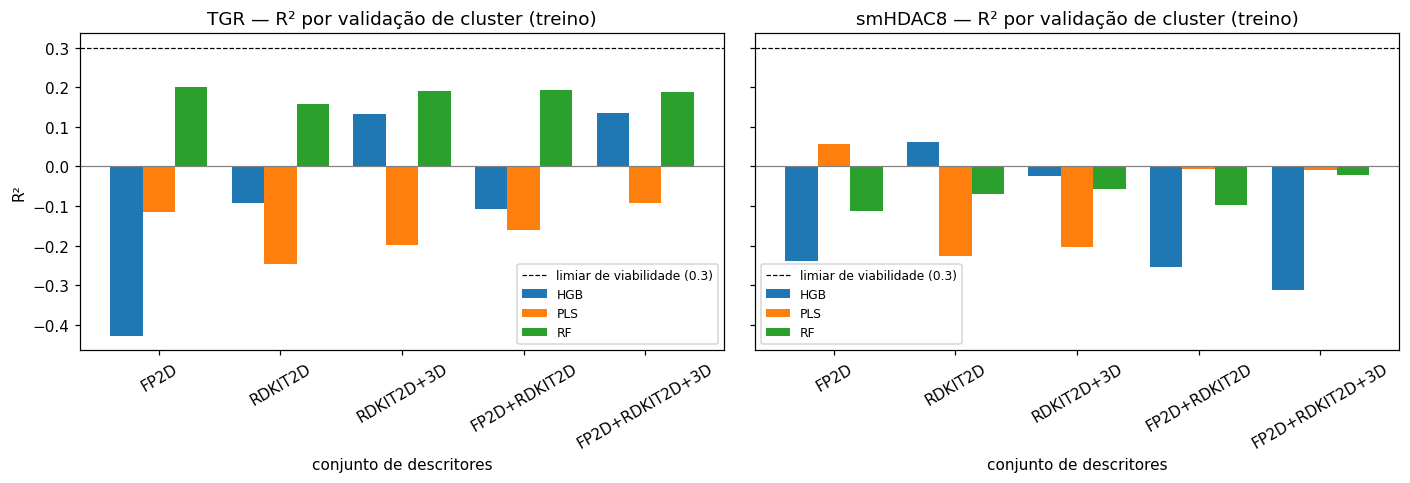

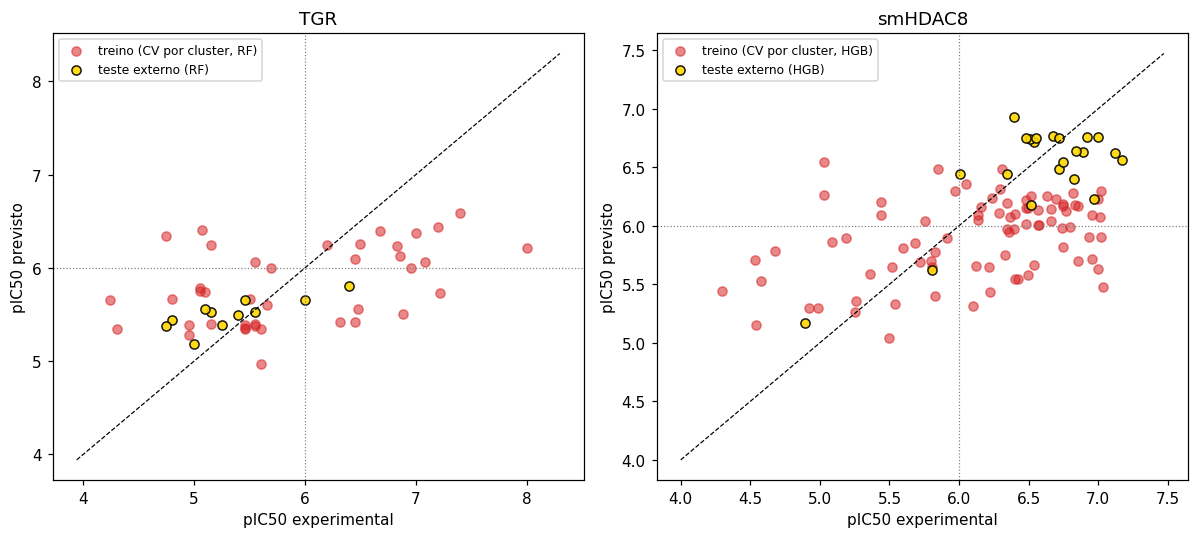

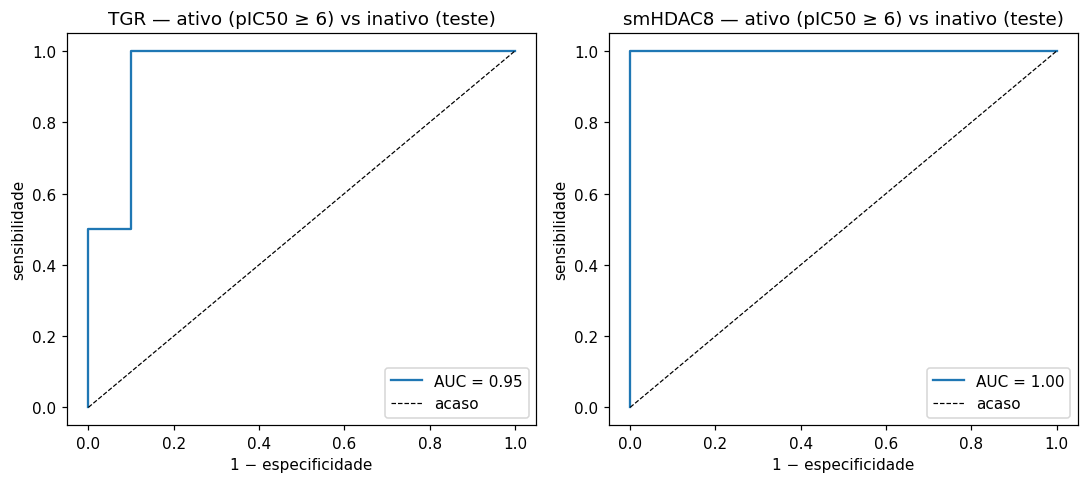

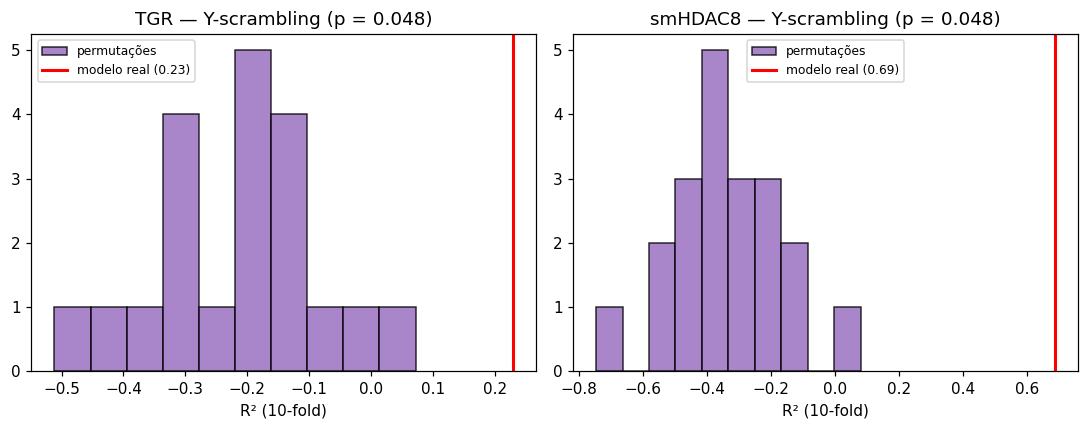

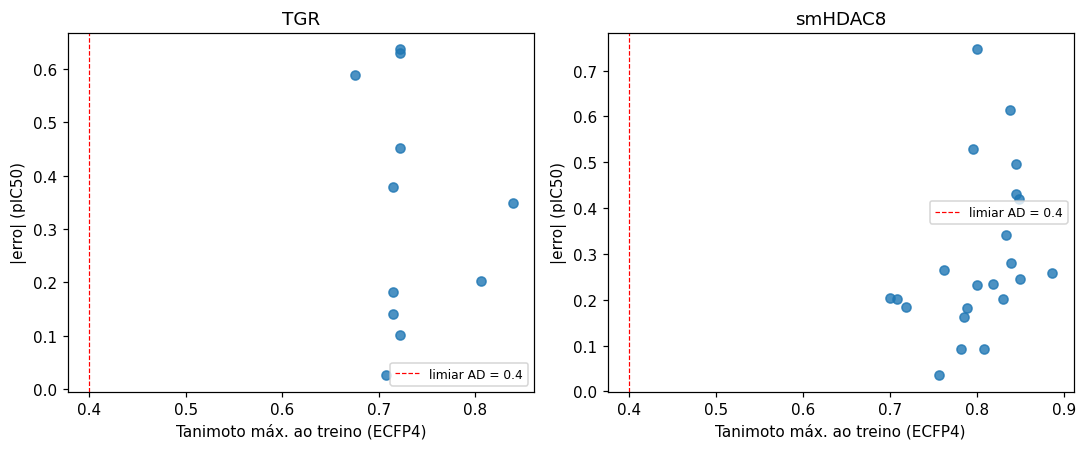

In [12]:
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 10})

# Fig. A — ablação (R² por cluster e aleatório)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, n in zip(axes, TARGETS):
    piv = ABL[n].pivot(index='conjunto', columns='modelo', values='R2_CV_cluster').reindex(list(FEATURE_SETS))
    piv.plot(kind='bar', ax=ax, width=0.8)
    ax.axhline(MIN_R2_VIABLE, color='k', ls='--', lw=0.8, label=f'limiar de viabilidade ({MIN_R2_VIABLE})')
    ax.axhline(0, color='grey', lw=0.8)
    ax.set_title(f'{n} — R² por validação de cluster (treino)')
    ax.set_xlabel('conjunto de descritores'); ax.set_ylabel('R²')
    ax.tick_params(axis='x', rotation=30)
    ax.legend(fontsize=8, loc='best')
plt.tight_layout(); plt.savefig('figuras/figA_ablacao_descritores.png', bbox_inches='tight'); plt.show()

# Fig. B — previsto vs experimental (CV por cluster no treino + teste externo)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, n in zip(axes, TARGETS):
    tr, te = SPLIT[n]['train'], SPLIT[n]['test']
    bm = max(FINAL[n], key=lambda m: FINAL[n][m]['R2_cluster'])
    pc = ABL_P[n][(FINAL[n][bm]['set'], bm)]['clu']
    pt = CONS[n]['pred_mean'].values if n in CONS else FINAL[n][bm]['pred_test']
    ax.scatter(tr['pIC50'], pc, alpha=0.55, label=f'treino (CV por cluster, {bm})', color='#d62728')
    ax.scatter(te['pIC50'], pt, alpha=0.9, label='teste externo' + (' (consenso)' if n in CONS else f' ({bm})'),
               color='gold', edgecolor='k')
    lo = min(tr['pIC50'].min(), te['pIC50'].min(), pc.min(), pt.min()) - 0.3
    hi = max(tr['pIC50'].max(), te['pIC50'].max(), pc.max(), pt.max()) + 0.3
    ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8)
    ax.axhline(PIC50_THR, color='grey', ls=':', lw=0.8); ax.axvline(PIC50_THR, color='grey', ls=':', lw=0.8)
    ax.set_xlabel('pIC50 experimental'); ax.set_ylabel('pIC50 previsto'); ax.set_title(n); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figuras/figB_previsto_vs_experimental.png', bbox_inches='tight'); plt.show()

# Fig. C — curvas ROC no teste (classificação)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, n in zip(axes, TARGETS):
    yt = SPLIT_C[n]['test']['y'].values
    prob = CLS_FINAL[n]['_prob_test']
    if len(np.unique(yt)) == 2:
        fpr, tpr, _ = roc_curve(yt, prob)
        ax.plot(fpr, tpr, label=f'AUC = {roc_auc_score(yt, prob):.2f}')
    ax.plot([0, 1], [0, 1], 'k--', lw=0.8, label='acaso')
    ax.set_title(f'{n} — ativo (pIC50 ≥ 6) vs inativo (teste)'); ax.set_xlabel('1 − especificidade'); ax.set_ylabel('sensibilidade')
    ax.legend()
plt.tight_layout(); plt.savefig('figuras/figC_roc_classificacao.png', bbox_inches='tight'); plt.show()

# Fig. D — Y-scrambling
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, n in zip(axes, TARGETS):
    ax.hist(YS[n]['perm'], bins=10, color='#9467bd', edgecolor='k', alpha=0.8, label='permutações')
    ax.axvline(YS[n]['R2_real'], color='r', lw=2, label=f"modelo real ({YS[n]['R2_real']:.2f})")
    ax.set_title(f"{n} — Y-scrambling (p = {YS[n]['p_empirico']:.3f})"); ax.set_xlabel('R² (10-fold)'); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figuras/figD_y_scrambling.png', bbox_inches='tight'); plt.show()

# Fig. E — domínio de aplicabilidade: erro vs similaridade ao treino
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, n in zip(axes, TARGETS):
    te = SPLIT[n]['test']
    bm = max(FINAL[n], key=lambda m: FINAL[n][m]['R2_cluster'])
    p = CONS[n]['pred_mean'].values if n in CONS else FINAL[n][bm]['pred_test']
    ax.scatter(SPLIT[n]['test_sim'], np.abs(te['pIC50'].values - p), alpha=0.8)
    ax.axvline(AD_THR, color='r', ls='--', lw=0.8, label=f'limiar AD = {AD_THR}')
    ax.set_xlabel('Tanimoto máx. ao treino (ECFP4)'); ax.set_ylabel('|erro| (pIC50)'); ax.set_title(n); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig('figuras/figE_dominio_aplicabilidade.png', bbox_inches='tight'); plt.show()

## 9. Triagem virtual no ZINC (com domínio de aplicabilidade e filtros mecanísticos)

**Como usar:** coloque os arquivos `.smi` (`SMILES ZINC_ID`) em `zinc_libs/` — por exemplo `zinc_amostra_15k.smi`, `substances.smi` (análogos do PZQ) e, **recomendado**, análogos dos inibidores mais potentes (tabela de sementes abaixo → busca por similaridade no ZINC22).
Se a pasta estiver vazia, o notebook pede o upload.

Regras: previsão só para compostos drug-like e com Tanimoto ≥ 0,30 ao conjunto conhecido do alvo; "no domínio" = Tanimoto ≥ 0,40. Previsões de regressão são limitadas à faixa do treino ± 1 log; previsões fora dela marcam `extrapolacao = True` (descritores fora do domínio) e excluem o composto das prioridades A/B. Prioridade **A** = no domínio + ativo previsto + sem PAINS + sem extrapolação (+ grupo de ligação ao zinco no HDAC8); **B** = ativo previsto + sem PAINS + sem extrapolação; **C** = demais. A coluna `Brenk` é informativa (alertas toxicofóricos, p. ex. nitroaromáticos) para a Discussão.

In [18]:
# ---- 9a. Sementes para a busca por similaridade no ZINC22
for n in TARGETS:
    s = CUR[n]['reg'].sort_values('pIC50', ascending=False).head(8)
    print(f'\n=== {n}: inibidores mais potentes (consulta para busca por similaridade, Tanimoto 40%) ===')
    print(s[['molecule_chembl_id', 'pIC50', 'smiles_std']].to_string(index=False))
    s.to_csv(f'tabelas/sementes_zinc_{n}.csv', index=False)

# ---- 9b. Modelos de implantação (reajustados com todos os dados do alvo)
DEPLOY = {}
for n in TARGETS:
    reg, cls = CUR[n]['reg'], CUR[n]['cls']
    dep = {'reg': {}, 'cls': {}}
    for mn, d in FINAL[n].items():
        if d['viavel']:
            X, _ = X_for(n, reg['smiles_std'], d['set'])
            dep['reg'][mn] = (d['set'], make_reg(mn).fit(X, reg['pIC50'].values))
    row = CLS_TAB[CLS_TAB['alvo'] == n].iloc[0]
    if bool(row['viavel_para_triagem']):
        X, _ = X_for(n, cls['smiles_std'], CLS_SET[n])
        for mn in ['RF', 'HGB']:
            dep['cls'][mn] = (CLS_SET[n], make_cls(mn).fit(X, cls['y'].values))
    DEPLOY[n] = dep
    ref = sorted(set(reg['smiles_std']) | set(cls['smiles_std']))
    dep['ref_ecfp'] = np.vstack([FEATS[n]['blocks']['ecfp4'][0][FEATS[n]['index'][s]] for s in ref])
    print(f"{n}: modelos de regressão viáveis = {list(dep['reg'])} | classificadores viáveis = {list(dep['cls'])}")
joblib.dump({n: {k: v for k, v in d.items()} for n, d in DEPLOY.items()}, 'models/deploy_v2.joblib')

# ---- 9c. Leitura das bibliotecas
def read_smi(path):
    d = pd.read_csv(path, sep=r'\s+', header=None, usecols=[0, 1], names=['smiles', 'zinc_id'], dtype=str)
    return d[d['smiles'].str.lower() != 'smiles']

for f in ['zinc_amostra_15k.smi', 'substances.smi']:
    if os.path.exists(f) and not os.path.exists(f'zinc_libs/{f}'):
        shutil.copy(f, f'zinc_libs/{f}')
if not glob.glob('zinc_libs/*.smi'):
    try:
        from google.colab import files
        print('Envie os arquivos .smi do ZINC (um ou mais):')
        for name, content in files.upload().items():
            open(f'zinc_libs/{name}', 'wb').write(content)
    except Exception:
        print('Nenhum .smi em zinc_libs/ — a triagem será pulada.')

libs = []
for p in sorted(glob.glob('zinc_libs/*.smi')):
    d = read_smi(p)
    d['origem'] = os.path.basename(p)
    libs.append(d)
    print(f'{os.path.basename(p)}: {len(d)} compostos')
LIB = pd.concat(libs, ignore_index=True) if libs else pd.DataFrame(columns=['smiles', 'zinc_id', 'origem'])
print('Total (bruto):', len(LIB))


=== TGR: inibidores mais potentes (consulta para busca por similaridade, Tanimoto 40%) ===
molecule_chembl_id    pIC50                                                        smiles_std
     CHEMBL3322287 8.000000               NC(=O)c1c(C(=O)N2CC(=O)N3CCc4ccccc4C3C2)no[n+]1[O-]
      CHEMBL570345 7.397940                          O=C(c1cccs1)c1no[n+]([O-])c1C(=O)c1cccs1
     CHEMBL1439384 7.221849                   COc1ccc([N+](=O)[O-])c(S(=O)(=O)c2ccc(Cl)cc2)n1
      CHEMBL576265 7.200659                                   N#Cc1c(C(=O)c2cccs2)no[n+]1[O-]
     CHEMBL3322292 7.080922 NC(=O)c1c(COc2ccc3c(c2)C2CN(C(=O)C4CCCCC4)CC(=O)N2CC3)no[n+]1[O-]
     CHEMBL1325877 7.000000                COc1ccc(C(=O)c2no[n+]([O-])c2C(=O)c2ccc(OC)cc2)cc1
      CHEMBL567637 6.958607                                      O=Cc1c(-c2ccccc2)no[n+]1[O-]
     CHEMBL1486739 6.886057                     COc1ccc(C(Nc2cc(C)ccn2)c2ccc3ccc(C)nc3c2O)cc1

=== smHDAC8: inibidores mais potentes (consulta para busca po

Saving pzq_zinc20.smi to pzq_zinc20 (1).smi
pzq_zinc20 (1).smi: 85 compostos
Total (bruto): 85


In [14]:
!mv "ZINC-downloader-2D-smi (1).uri" zinc2.uri
!mv "ZINC-downloader-2D-smi.uri" zinc1.uri
!head -n 3 zinc1.uri                      # confirma que são URLs
!mkdir -p zinc
!head -n 20 zinc1.uri | xargs -P 8 -n 1 wget -q -nc -P zinc
!ls -lh zinc | head

http://files.docking.org/2D/BA/BAAA.smi
http://files.docking.org/2D/BA/BAAB.smi
http://files.docking.org/2D/BA/BAAC.smi
^C
total 0


In [15]:
!ls -lh zinc
!du -sh zinc

total 0
4.0K	zinc


In [16]:
from google.colab import files
import pandas as pd
up = files.upload()
df = pd.read_csv(list(up.keys())[0])
print(df.shape)
print(df.columns.tolist())

Saving substances.csv to substances.csv
(85, 2)
['zinc_id', 'smiles']


In [17]:
from google.colab import files
df[['smiles', 'zinc_id']].to_csv('pzq_zinc20.smi', sep=' ', header=False, index=False)
files.download('pzq_zinc20.smi')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# ---- 9d. Padronização, propriedades e domínio de aplicabilidade
# O tautômero canônico do RDKit converte hidroxamatos para a forma hidroxímica (C(O)=NO): os dois são reconhecidos.
ZBG = {'hidroxamato': ['[CX3](=O)[NX3][OX2H1]', '[CX3]([OX2H1])=[NX2][OX2H1]'],
       'o-aminoanilida': ['[NX3;H2]c:c[NX3;H1]C(=O)', '[NX3;H2]c:c[NX2]=C[OX2H1]'],
       'tiol': ['[SX2;H1]'],
       'cetona CF3 (fraco)': ['[CX3](=O)C(F)(F)F'],
       'ácido carboxílico (fraco)': ['[CX3](=O)[OX2H1]']}
ZBG_FORTE = {'hidroxamato', 'o-aminoanilida', 'tiol'}
ZBG_PAT = {k: [Chem.MolFromSmarts(x) for x in v] for k, v in ZBG.items()}
CAT_PAINS = FilterCatalog(FilterCatalogParams(FilterCatalogParams.FilterCatalogs.PAINS))
CAT_BRENK = FilterCatalog(FilterCatalogParams(FilterCatalogParams.FilterCatalogs.BRENK))

def first_match(cat, m):
    e = cat.GetFirstMatch(m)
    return e.GetDescription() if e is not None else ''

RESULTS = {}
if len(LIB):
    LIB['smiles_std'] = [standardize(s) for s in tqdm(LIB['smiles'], desc='padronizando biblioteca')]
    LIB = LIB.dropna(subset=['smiles_std']).drop_duplicates('smiles_std').reset_index(drop=True)
    mols = [Chem.MolFromSmiles(s) for s in LIB['smiles_std']]
    phys, _ = block_phys(mols)
    ecfp = block_ecfp(mols)
    LIB['MW'], LIB['LogP'], LIB['HBD'], LIB['HBA'], LIB['TPSA'] = phys[:, 0], phys[:, 1], phys[:, 2], phys[:, 3], phys[:, 4]
    LIB['violacoes_Lipinski'] = lipinski_violations(phys)
    LIB['drug_like'] = LIB['violacoes_Lipinski'] <= 1
    print(f"Biblioteca padronizada: {len(LIB)} estruturas únicas | drug-like: {int(LIB['drug_like'].sum())}")

    for n in TARGETS:
        dep = DEPLOY[n]
        if not dep['reg'] and not dep['cls']:
            print(f'\n[{n}] sem modelo viável (regressão: R² < {MIN_R2_VIABLE} e ρ < {MIN_RHO_VIABLE} por cluster; classificação: AUC < {MIN_AUC_VIABLE}) — triagem NÃO executada. '
                  'Reportar como resultado negativo/exploratório.')
            continue
        LIB[f'maxsim_{n}'] = max_tanimoto(ecfp, dep['ref_ecfp'])
        sel = LIB['drug_like'] & (LIB[f'maxsim_{n}'] >= AD_FLOOR)
        print(f"\n[{n}] drug-like com Tanimoto ≥ {AD_FLOOR}: {int(sel.sum())} | no domínio (≥ {AD_THR}): "
              f"{int((LIB['drug_like'] & (LIB[f'maxsim_{n}'] >= AD_THR)).sum())}")
        if sel.sum() == 0:
            print('   nenhum composto da biblioteca está próximo o bastante do espaço químico do alvo. '
                  'Use as sementes acima para gerar uma biblioteca focada (busca por similaridade no ZINC).')
            continue
        sub = LIB[sel].copy()
        sub_mols = [mols[i] for i in sub.index]
        sets = [s for s, _ in list(dep['reg'].values()) + list(dep['cls'].values())]
        blocks = featurize(sub_mols, sorted({b for s in sets for b in FEATURE_SETS[s]}))
        out = pd.DataFrame(index=sub.index)
        preds, extrap = [], np.zeros(len(sub), dtype=bool)
        yk = CUR[n]['reg']['pIC50']
        lo, hi = yk.min() - 1.0, yk.max() + 1.0   # faixa plausível: treino ± 1 unidade log
        for mn, (fs, est) in dep['reg'].items():
            Xs, _ = assemble(blocks, fs)
            raw = np.ravel(est.predict(Xs))
            extrap |= (raw < lo) | (raw > hi)       # previsão absurda = descritores fora do domínio
            out[f'pIC50_{mn}'] = np.clip(raw, lo, hi)
            preds.append(out[f'pIC50_{mn}'].values)
        if preds:
            P = np.vstack(preds)
            out['pIC50_consenso'] = P.mean(axis=0)
            out['pIC50_dp'] = P.std(axis=0, ddof=1) if len(P) > 1 else 0.0
            out['CV%'] = out['pIC50_dp'] / out['pIC50_consenso'] * 100
        out['extrapolacao'] = extrap
        probs = [est.predict_proba(assemble(blocks, fs)[0])[:, 1] for fs, est in dep['cls'].values()]
        if probs:
            out['p_ativo'] = np.mean(probs, axis=0)
        res = pd.concat([sub[['zinc_id', 'origem', 'smiles_std', 'MW', 'LogP', 'HBD', 'HBA', 'TPSA', f'maxsim_{n}']]
                         .rename(columns={f'maxsim_{n}': 'maxsim'}), out], axis=1)
        res['no_dominio'] = res['maxsim'] >= AD_THR
        res['PAINS'] = [first_match(CAT_PAINS, m) for m in sub_mols]
        res['Brenk'] = [first_match(CAT_BRENK, m) for m in sub_mols]
        if n == 'smHDAC8':
            zb = [[k for k, ps in ZBG_PAT.items() if any(m.HasSubstructMatch(p) for p in ps)] for m in sub_mols]
            res['ZBG'] = ['; '.join(z) for z in zb]
            res['ZBG_forte'] = [any(k in ZBG_FORTE for k in z) for z in zb]
        ativo = (res.get('pIC50_consenso', pd.Series(np.nan, index=res.index)) >= PIC50_THR) | \
                (res.get('p_ativo', pd.Series(0.0, index=res.index)) >= 0.5)
        zbg_ok = res['ZBG_forte'] if 'ZBG_forte' in res else pd.Series(True, index=res.index)
        limpo = (res['PAINS'] == '') & ~res['extrapolacao']
        res['prioridade'] = np.where(res['no_dominio'] & ativo & limpo & zbg_ok, 'A',
                                     np.where(ativo & limpo, 'B', 'C'))
        sort_col = 'p_ativo' if 'p_ativo' in res else 'pIC50_consenso'
        res = res.sort_values(['prioridade', sort_col], ascending=[True, False]).reset_index(drop=True)
        RESULTS[n] = res
        res.to_csv(f'tabelas/triagem_{n}.csv', index=False)
        print(f"   prioridade A: {(res['prioridade'] == 'A').sum()} | B: {(res['prioridade'] == 'B').sum()} | C: {(res['prioridade'] == 'C').sum()}")
        print(res.head(15)[['zinc_id', 'origem', 'maxsim', 'prioridade'] + [c for c in ['pIC50_consenso', 'CV%', 'p_ativo', 'ZBG', 'PAINS'] if c in res]].round(3).to_string(index=False))
else:
    print('Sem biblioteca — triagem pulada.')

padronizando biblioteca:   0%|          | 0/85 [00:00<?, ?it/s]

Biblioteca padronizada: 79 estruturas únicas | drug-like: 79

[TGR] sem modelo viável (regressão: R² < 0.3 e ρ < 0.5 por cluster; classificação: AUC < 0.65) — triagem NÃO executada. Reportar como resultado negativo/exploratório.

[smHDAC8] drug-like com Tanimoto ≥ 0.3: 0 | no domínio (≥ 0.4): 0
   nenhum composto da biblioteca está próximo o bastante do espaço químico do alvo. Use as sementes acima para gerar uma biblioteca focada (busca por similaridade no ZINC).


In [20]:
# ---- 9e. Priorização dos análogos do PZQ por similaridade às sementes do TGR
SEEDS_TGR = {
    'CHEMBL3322287': 'NC(=O)c1c(C(=O)N2CC(=O)N3CCc4ccccc4C3C2)no[n+]1[O-]',
    'CHEMBL570345':  'O=C(c1cccs1)c1no[n+]([O-])c1C(=O)c1cccs1',
    'CHEMBL1439384': 'COc1ccc([N+](=O)[O-])c(S(=O)(=O)c2ccc(Cl)cc2)n1',
    'CHEMBL576265':  'N#Cc1c(C(=O)c2cccs2)no[n+]1[O-]',
    'CHEMBL3322292': 'NC(=O)c1c(COc2ccc3c(c2)C2CN(C(=O)C4CCCCC4)CC(=O)N2CC3)no[n+]1[O-]',
    'CHEMBL1325877': 'COc1ccc(C(=O)c2no[n+]([O-])c2C(=O)c2ccc(OC)cc2)cc1',
    'CHEMBL567637':  'O=Cc1c(-c2ccccc2)no[n+]1[O-]',
    'CHEMBL1486739': 'COc1ccc(C(Nc2cc(C)ccn2)c2ccc3ccc(C)nc3c2O)cc1',
}
seed_mols = [Chem.MolFromSmiles(s) for s in (standardize(x) for x in SEEDS_TGR.values()) if s]
seed_ecfp = block_ecfp(seed_mols)

LIB['maxsim_TGR_sementes'] = max_tanimoto(ecfp, seed_ecfp)
LIB['PAINS'] = [first_match(CAT_PAINS, m) for m in mols]
LIB['Brenk'] = [first_match(CAT_BRENK, m) for m in mols]
LIB['prioridade_TGR'] = np.where(
    LIB['drug_like'] & (LIB['PAINS'] == '') & (LIB['maxsim_TGR_sementes'] >= AD_THR), 'A',
    np.where(LIB['drug_like'] & (LIB['maxsim_TGR_sementes'] >= AD_FLOOR), 'B', 'C'))

res_tgr = LIB.sort_values(['prioridade_TGR', 'maxsim_TGR_sementes'],
                          ascending=[True, False]).reset_index(drop=True)
res_tgr.to_csv('tabelas/priorizacao_TGR_similaridade.csv', index=False)
print(res_tgr['prioridade_TGR'].value_counts().to_string())
print(res_tgr.head(15)[['zinc_id', 'maxsim_TGR_sementes', 'prioridade_TGR',
                        'MW', 'LogP', 'PAINS', 'Brenk']].round(3).to_string(index=False))

prioridade_TGR
A    54
C    15
B    10
         zinc_id  maxsim_TGR_sementes prioridade_TGR      MW  LogP PAINS   Brenk
ZINC000082151414                0.575              A 328.412 2.240              
ZINC000082151416                0.575              A 328.412 2.240              
ZINC000028823655                0.568              A 327.428 2.117       aniline
ZINC000028823656                0.568              A 327.428 2.117       aniline
ZINC000036138040                0.548              A 315.373 0.880              
ZINC000036138038                0.548              A 315.373 0.880              
ZINC000036138123                0.547              A 346.858 3.188              
ZINC000036138125                0.547              A 346.858 3.188              
ZINC000049072285                0.541              A 313.401 2.034              
ZINC000049072283                0.541              A 313.401 2.034              
ZINC000039434573                0.532              A 298.386 2.145    

In [21]:
furoxano = Chem.MolFromSmarts('[#6]1~[#7]~[#8]~[#7+]([O-])~[#6]~1')
LIB['furoxano'] = [m.HasSubstructMatch(furoxano) for m in mols]
print(LIB['furoxano'].sum(), 'de', len(LIB), 'têm furoxano')

0 de 79 têm furoxano


In [22]:
print(sum(m.HasSubstructMatch(furoxano) for m in seed_mols), 'de', len(seed_mols), 'sementes têm furoxano (esperado: 6)')

6 de 8 sementes têm furoxano (esperado: 6)


In [23]:
LIB['flat'] = [Chem.MolToSmiles(m, isomericSmiles=False) for m in mols]
print(LIB['flat'].nunique(), 'estruturas distintas, de', len(LIB))

40 estruturas distintas, de 79


In [24]:
res_tgr['flat'] = [Chem.MolToSmiles(Chem.MolFromSmiles(s), isomericSmiles=False) for s in res_tgr['smiles_std']]
res_tgr['n_estereoisomeros'] = res_tgr.groupby('flat')['flat'].transform('size')
uniq = res_tgr.drop_duplicates('flat').reset_index(drop=True)
uniq.to_csv('tabelas/priorizacao_TGR_unicos.csv', index=False)
print(len(uniq), 'estruturas únicas')
print(uniq['prioridade_TGR'].value_counts().to_string())

40 estruturas únicas
prioridade_TGR
A    26
C     9
B     5


In [25]:
from google.colab import files
files.download('tabelas/priorizacao_TGR_unicos.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Resumo e exportação

In [28]:
print('================ RESUMO CONSOLIDADO PARA O TCC ================')
print('\n[1. Funil de Curadoria]');                     print(FUNIL.to_string())
print('\n[2. Critérios de Lipinski]');                  print(LIP.to_string(index=False))
print('\n[3. Desempenho Teste Externo — Regressão]');    print(TESTE.round(3).to_string(index=False))
print('\n[4. Desempenho Teste Externo — Classificação]');print(CLS_TAB.round(3).to_string(index=False))
print('\n[5. Validação por Y-Scrambling]');             print(YS_TAB.round(3).to_string(index=False))
print('\n[6. Domínio de Aplicabilidade no Teste]');       print(AD_TAB.round(3).to_string(index=False))

print('\n[7. Triagem Virtual Tradicional (Se houver)]')
for n, r in RESULTS.items():
    print(f'   - Alvo {n} -> Prioridade A: {(r.prioridade == "A").sum()} | B: {(r.prioridade == "B").sum()} | Total: {len(r)}')
    top = r[r.prioridade == 'A']
    if len(top):
        top[['zinc_id', 'smiles_std']].to_csv(f'tabelas/shortlist_{n}_para_docking.smi', sep=' ', header=False, index=False)

print('\n[8. Priorização de Análogos (Sementes TGR)]')
if 'prioridade_TGR' in res_tgr.columns:
    print(f'   - Total avaliado por similaridade: {len(res_tgr)}')
    print('   - Distribuição de classes (Completo):')
    print(res_tgr['prioridade_TGR'].value_counts().to_string())
if 'uniq' in locals() or 'uniq' in globals():
    print(f'   - Estruturas planas (flat) exclusivas remanescentes: {len(uniq)}')
    print('   - Distribuição de classes (Estruturas Únicas):')
    print(uniq['prioridade_TGR'].value_counts().to_string())

# Salvamento do deploy e modelos finais compactados
joblib.dump({'FINAL': {n: {m: {k: v for k, v in d.items() if k != 'pred_test'} for m, d in dd.items()} for n, dd in FINAL.items()},
             'CLS_SET': CLS_SET}, 'models/finais_v2.joblib')

# Criação dos pacotes de exportação
shutil.make_archive('resultados_TCC_v2_figuras', 'zip', '.', 'figuras')
shutil.make_archive('resultados_TCC_v2_tabelas', 'zip', '.', 'tabelas')
print('\n================ EXPORTAÇÃO CONCLUÍDA ================')
print('Arquivos gerados com sucesso: resultados_TCC_v2_figuras.zip e resultados_TCC_v2_tabelas.zip.')

================ RESUMO CONSOLIDADO PARA O TCC ================

[1. Funil de Curadoria]
                                                        TGR   smHDAC8
1. registros IC50 brutos (ChEMBL)                        59       260
2. com valor > 0, unidade nM e SMILES                    58       258
3. SMILES padronizado com sucesso                        58       258
    dos quais censurados (relação ≠ '=')                  6       106
4. valores exatos ('=') — base da regressão              52       152
5. estruturas únicas (após padronização)                 51       107
6. sem réplicas discordantes (> 1 log)                   51       106
7. classificação: estruturas com rótulo inequívoco       57       203
    ativos / inativos (IC50 ≤ 1 µM)                 19 / 38  74 / 129

[2. Critérios de Lipinski]
   alvo   N  0 violações  1 violação  ≥2 violações drug-like (≤1)
    TGR  51           48           3             0         100.0%
smHDAC8 106           95           9             2 